# CHILLED — EDA: LBNL FDD Chiller Plant Data Sets

Source archive: `opensource_dataset/LBNL/LBNL FDD Chiller Plant Data Sets.zip`

Lawrence Berkeley National Laboratory's fault-detection-and-diagnostics benchmark for
**whole chiller plants**. Where ASHRAE RP-1043 instruments a single machine on a test rig, this
dataset is a **Modelica simulation of a complete plant** — three chillers, three cooling towers,
condenser-water and primary/secondary chilled-water loops — run over a **full year of weather at
1-minute resolution**.

The archive holds **24 CSV files**: one fault-free baseline plus 23 fault scenarios, each a
`(fault type, severity)` pair. Every file is an independent year-long run of the *same* plant
under the *same* weather, so a baseline and a fault file are directly comparable sample by
sample — which is exactly what makes it useful for FDD.

### ⚠️ The archive is never extracted
Uncompressed the 24 files total **≈ 10.3 GB**. This notebook streams the two files it needs
straight out of the zip with `zipfile` + `polars.read_csv` — **nothing is written to disk**, and
only the two selected scenarios are ever decompressed. A single file loads in ~2 s and occupies
~330 MB in memory.

### What this notebook does
1. Lists the fault catalogue in the archive.
2. Loads **one healthy** and **one faulty** scenario and profiles them
   (min/max/mean, nulls, sampling rate, gaps, constant channels, plant operating modes).
3. Builds the **correlation matrix plot** (same idiom as `eda.ipynb`) for both, plus the
   healthy→faulty correlation *shift*.
4. Runs **PCA on the healthy year**, then projects both into that basis and plots
   **PC1–PC3** over the **whole year** and over a **single day**.

### Series chosen
| role | file | what it is |
|---|---|---|
| **healthy** | `ChillerPlant.csv` | the fault-free baseline year |
| **faulty**  | `ChillerPlant_chiller_fouling_065.csv` | chiller evaporator/condenser **fouling**, severity factor 0.65 — the most severe fouling case in the archive, and the direct analogue of the `cf30` condenser-fouling run in `eda_ashrae.ipynb` |

In [1]:
import zipfile

import numpy as np
import polars as pl

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

ZIP_PATH = "opensource_dataset/LBNL/LBNL FDD Chiller Plant Data Sets.zip"

HEALTHY_FILE = "ChillerPlant.csv"
FAULTY_FILE = "ChillerPlant_chiller_fouling_065.csv"

HEALTHY = "baseline"
FAULTY = "chiller_fouling_065"

pl.Config.set_tbl_rows(20)

polars.config.Config

## 1. Fault catalogue in the archive

Everything is inspected from the zip's central directory — no decompression.

In [2]:
with zipfile.ZipFile(ZIP_PATH) as z:
    members = z.infolist()

catalogue = pl.DataFrame({
    "file": [m.filename for m in members],
    "compressed_MB": [round(m.compress_size / 1e6, 1) for m in members],
    "uncompressed_MB": [round(m.file_size / 1e6, 1) for m in members],
}).with_columns(
    pl.col("file").str.replace(r"^ChillerPlant_?", "").str.replace(r"\.csv$", "")
      .replace("", "(fault-free baseline)").alias("scenario")
).select("scenario", "file", "compressed_MB", "uncompressed_MB").sort("scenario")

print(f"{catalogue.height} scenarios, "
      f"{catalogue['uncompressed_MB'].sum() / 1000:.1f} GB uncompressed, "
      f"{catalogue['compressed_MB'].sum() / 1000:.1f} GB as the zip on disk")

with pl.Config(tbl_rows=-1, fmt_str_lengths=65):
    display(catalogue)

24 scenarios, 10.3 GB uncompressed, 1.6 GB as the zip on disk


scenario,file,compressed_MB,uncompressed_MB
str,str,f64,f64
"""(fault-free baseline)""","""ChillerPlant.csv""",68.5,429.4
"""bypass_leakage_025""","""ChillerPlant_bypass_leakage_025.csv""",66.5,431.6
"""bypass_leakage_050""","""ChillerPlant_bypass_leakage_050.csv""",56.8,421.6
"""bypass_leakage_075""","""ChillerPlant_bypass_leakage_075.csv""",53.1,429.6
"""bypass_stuck_050""","""ChillerPlant_bypass_stuck_050.csv""",56.0,427.8
"""bypass_stuck_075""","""ChillerPlant_bypass_stuck_075.csv""",53.1,429.6
"""chiller_bias_-1""","""ChillerPlant_chiller_bias_-1.csv""",65.7,425.3
"""chiller_bias_-2""","""ChillerPlant_chiller_bias_-2.csv""",65.4,429.1
"""chiller_bias_1""","""ChillerPlant_chiller_bias_1.csv""",64.3,427.0


The naming scheme decodes as `<subsystem>_<fault>_<severity>`:

| family | scenarios | meaning |
|---|---|---|
| `chiller_fouling_*` | 065, 095 | heat-exchanger fouling; the number is the retained-performance factor, so **lower = worse** |
| `coolingtower_fouling_*` | 065, 080, 095 | tower fill fouling, same convention |
| `chiller_bias_*` | ±1, ±2 | chilled-water temperature **sensor bias**, in °F |
| `coolingtower_bias_*` | ±1, ±2 | tower supply-water temperature sensor bias |
| `secondary_chilled_water_pressure_bias_*` | ±010, ±020 | secondary-loop differential-pressure sensor bias |
| `bypass_leakage_*` | 025, 050, 075 | bypass valve leaking through when it should be shut |
| `bypass_stuck_*` | 050, 075 | bypass valve stuck at a fixed position |
| `coolingtower_PI` | — | mistuned cooling-tower PI controller |

Note the two *classes* of fault here that RP-1043 does not have: **sensor faults** (`*_bias_*`)
and **control faults** (`*_stuck_*`, `coolingtower_PI`). Those are invisible to a physics-based
residual on the biased sensor itself and have to be caught through the relationships *between*
channels — i.e. exactly the correlation structure this notebook maps.

## 2. Loading, without extracting

In [3]:
def load_scenario(member: str) -> pl.DataFrame:
    # stream one CSV out of the zip; nothing is written to disk
    with zipfile.ZipFile(ZIP_PATH) as z:
        with z.open(member) as f:
            return pl.read_csv(f, try_parse_dates=True)


healthy = load_scenario(HEALTHY_FILE)
faulty = load_scenario(FAULTY_FILE)

print(f"healthy '{HEALTHY}': {healthy.shape}")
print(f"faulty  '{FAULTY}': {faulty.shape}")
healthy.head()

healthy 'baseline': (525540, 78)
faulty  'chiller_fouling_065': (525540, 78)


Datetime,CDWL_CW_FLOW,CDWL_PM_POW_1,CDWL_PM_POW_2,CDWL_PM_POW_3,CDWL_RW_TEMP,CDWL_SW_TEMP,CHL_CD_FLOW_1,CHL_CD_FLOW_2,CHL_CD_FLOW_3,CHL_COMP_SPD_CTRL_1,CHL_COMP_SPD_CTRL_2,CHL_COMP_SPD_CTRL_3,CHL_CW_FLOW_1,CHL_CW_FLOW_2,CHL_CW_FLOW_3,CHL_POW_1,CHL_POW_2,CHL_POW_3,CHL_SWCD_TEMP_1,CHL_SWCD_TEMP_2,CHL_SWCD_TEMP_3,CHL_RW_TEMP_1,CHL_RW_TEMP_2,CHL_RW_TEMP_3,CHL_STA_1,CHL_STA_2,CHL_STA_3,CHL_RWCD_TEMP_1,CHL_RWCD_TEMP_2,CHL_RWCD_TEMP_3,CHL_SW_TEMP_1,CHL_SW_TEMP_2,CHL_SW_TEMP_3,CT_FAN_SPD_1,CT_FAN_SPD_2,CT_FAN_SPD_3,…,CT_FLOW_2,CT_FLOW_3,CT_POW_1,CT_POW_2,CT_POW_3,CT_RW_TEMP_1,CT_RW_TEMP_2,CT_RW_TEMP_3,CT_STA_1,CT_STA_2,CT_STA_3,CT_SW_TEMPSPT,CT_SW_TEMP_1,CT_SW_TEMP_2,CT_SW_TEMP_3,CWL_PRI_CW_FLOW,CWL_PRI_PM_POW_1,CWL_PRI_PM_POW_2,CWL_PRI_PM_POW_3,CWL_PRI_RW_TEMP,CWL_PRI_SW_TEMP,CWL_PRI_SW_TEMPSPT,CWL_SEC_CW_FLOW,CWL_SEC_DP,CWL_SEC_DPSPT,CWL_SEC_LOAD,CWL_SEC_PM_POW_1,CWL_SEC_PM_POW_2,CWL_SEC_PM_SPD_1,CWL_SEC_PM_SPD_2,CWL_SEC_PM_STA_1,CWL_SEC_PM_STA_2,CWL_SEC_RW_TEMP,CWL_SEC_SW_TEMP,OA_TEMP,OA_TEMP_WB,TWV_CTRL
datetime[μs],f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2018-01-01 01:00:00,321.582963,46.084146,0.0,0.0,69.188995,61.984875,321.582107,0.000429,0.000429,0.497262,0.0,0.0,279.324281,0.000372,0.000372,69.507398,0.0,0.0,69.17861,74.99603,74.99603,57.255424,42.227337,42.227337,1.0,0.0,0.0,62.26277,75.55997,75.55997,51.432564,42.049248,42.049248,0.341687,0.0,0.0,…,0.000222,0.000222,0.49946,0.0,0.0,69.178665,68.70455,68.70455,1.0,0.0,0.0,60.007996,61.911266,69.697495,69.697495,279.325015,15.021188,0.0,0.0,57.26229,51.431625,53.999626,461.473576,529.201971,960.960802,22551.24,53.638358,0.0,1.0,0.0,1.0,0.0,56.816963,57.150177,9.070051,10.355011,0.0
2018-01-01 01:01:00,321.582963,46.084146,0.0,0.0,68.880936,61.921814,321.582107,0.000429,0.000429,0.4772221,0.0,0.0,279.324281,0.000372,0.000372,66.280762,0.0,0.0,68.87072,74.99603,74.99603,57.055916,42.227337,42.227337,1.0,0.0,0.0,62.199715,75.559906,75.559906,51.460247,42.049248,42.049248,0.333905,0.0,0.0,…,0.000222,0.000222,0.460999,0.0,0.0,68.87077,68.70455,68.70455,1.0,0.0,0.0,60.007996,61.85073,69.697495,69.697495,279.325015,15.021188,3.1077e-21,1.0415e-21,57.062508,51.45926,53.999626,461.473576,529.201971,960.960802,21665.527,53.638358,0.0,1.0,0.0,1.0,0.0,56.630524,56.950665,8.771828,10.040033,0.0
2018-01-01 01:02:00,321.582963,46.084146,3.5126e-18,1.6000e-34,68.57788,61.86161,321.582107,0.000429,0.000429,0.457744,0.0,0.0,279.324281,0.000372,0.000372,63.233582,0.0,0.0,68.56789,74.99603,74.99603,56.863213,42.227394,42.227394,1.0,0.0,0.0,62.139565,75.559906,75.559906,51.488262,42.049248,42.049248,0.3270085,0.0,0.0,…,0.000222,0.000222,0.425439,0.0,0.0,68.56793,68.70455,68.70455,1.0,0.0,0.0,60.007996,61.793,69.697495,69.697495,279.325015,15.021188,0.0,0.0,56.86953,51.487328,53.999626,461.473576,529.201971,960.960802,20804.45,53.638358,0.0,1.0,0.0,1.0,0.0,56.45057,56.757965,8.786055,10.055031,0.0
2018-01-01 01:03:00,321.582963,46.084146,0.0,0.0,68.299484,61.80426,321.582107,0.000429,0.000429,0.482627,0.0,0.0,279.324281,0.000372,0.000372,66.893384,0.0,0.0,68.29224,74.99603,74.99603,58.33236,42.227394,42.227394,1.0,0.0,0.0,62.082268,75.559906,75.559906,51.595047,42.049248,42.049248,0.3208565,0.0,0.0,…,0.000222,0.000222,0.392423,0.0,0.0,68.29229,68.70455,68.70455,1.0,0.0,0.0,60.007996,61.737957,69.697495,69.697495,279.325015,15.021188,0.0,0.0,58.238647,51.58725,53.999626,754.161433,864.846296,960.960802,0.0,52.330258,44.184977,1.0,1.0,1.0,1.0,61.19095,58.270123,8.800337,10.070026,0.0
2018-01-01 01:04:00,321.582963,46.084146,0.0,0.0,68.2412,61.76136,321.582107,0.000429,0.000429,0.6267811,0.0,0.0,279.324281,0.000372,0.000372,91.014646,0.0,0.0,68.2445,74.99603,74.99603,60.616966,42.227394,42.227394,1.0,0.0,0.0,62.039696,75.559906,75.559906,51.910744,42

## 3. General description of the dataset

### 3.1 Shape, time span and sampling rate

In [4]:
def profile(df: pl.DataFrame, label: str) -> dict:
    ts = df["Datetime"]
    dt = ts.diff().drop_nulls().dt.total_seconds()
    nominal = dt.median()
    span = ts.max() - ts.min()
    return {
        "series": label,
        "rows": df.height,
        "columns": df.width,
        "start": str(ts.min()),
        "end": str(ts.max()),
        "duration_days": round(span.total_seconds() / 86400, 2),
        "dt_median_s": nominal,
        "dt_min_s": dt.min(),
        "dt_max_s": dt.max(),
        "pct_dt_exactly_nominal": round(100 * dt.filter(dt == nominal).len() / dt.len(), 3),
        "n_gaps_ge_2x": dt.filter(dt >= nominal * 2).len(),
        "expected_rows_on_grid": int(round(span.total_seconds() / nominal)) + 1,
        "duplicate_timestamps": df.height - ts.n_unique(),
        "null_cells": int(df.null_count().sum_horizontal().item()),
        "nan_cells": int(sum(df[c].is_nan().sum() for c, t in df.schema.items() if t == pl.Float64)),
    }


overview = pl.DataFrame(
    [profile(healthy, f"healthy · {HEALTHY}"), profile(faulty, f"faulty · {FAULTY}")],
    schema_overrides={"start": pl.Utf8, "end": pl.Utf8},
)

with pl.Config(tbl_cols=-1, fmt_str_lengths=40):
    display(overview.transpose(include_header=True, column_names="series"))

column,healthy · baseline,faulty · chiller_fouling_065
str,str,str
"""rows""","""525540""","""525540"""
"""columns""","""78""","""78"""
"""start""","""2018-01-01 01:00:00""","""2018-01-01 01:00:00"""
"""end""","""2018-12-31 23:59:00""","""2018-12-31 23:59:00"""
"""duration_days""","""364.96""","""364.96"""
"""dt_median_s""","""60.0""","""60.0"""
"""dt_min_s""","""60""","""60"""
"""dt_max_s""","""60""","""60"""
"""pct_dt_exactly_nominal""","""100.0""","""100.0"""


**Read-out**

* **Sampling rate: exactly one sample per minute**, for the whole year — every single step is
  60 s, there are **no gaps, no duplicate timestamps and no missing rows**. The row count equals
  the ideal grid length. That is what a simulation output looks like, and it is the single
  biggest practical difference to the production data in `eda.ipynb`.
* The year runs **2018-01-01 01:00 → 2018-12-31 23:59**. Note it starts at **01:00, not 00:00** —
  the first hour is the simulation warm-up and is not in the file, so the year is
  **525 540 rows, not the 525 600** a full year of minutes would give. Anything that assumes a
  complete calendar year will be off by 60 rows.
* **Zero nulls, zero NaNs.** Again: simulation output. Any missing-data handling you build must
  be validated on real telemetry, not here.
* Both scenarios have **identical shape and identical timestamps**, so healthy and faulty can be
  compared sample-by-sample — the baseline is a true counterfactual, not just a similar period.

### 3.2 Per-channel statistics (min / max / mean / nulls)

In [5]:
def describe_full(df: pl.DataFrame) -> pl.DataFrame:
    num = [c for c, t in df.schema.items() if t in (pl.Float64, pl.Int64)]
    d = df.select(num).describe().transpose(include_header=True, column_names="statistic")
    return (
        d.rename({"column": "sensor"})
        .with_columns(pl.col("count", "null_count", "mean", "std", "min", "max", "25%", "50%", "75%")
                      .cast(pl.Float64))
        .with_columns((pl.col("max") - pl.col("min")).alias("range"))
        .select("sensor", "null_count", "mean", "std", "min", "25%", "50%", "75%", "max", "range")
    )


with pl.Config(tbl_rows=-1, tbl_cols=-1, fmt_str_lengths=45, float_precision=3):
    display(describe_full(healthy))

sensor,null_count,mean,std,min,25%,50%,75%,max,range
str,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""CDWL_CW_FLOW""",0.000,362.989,111.808,321.578,321.583,321.583,321.583,964.775,643.197
"""CDWL_PM_POW_1""",0.000,23.501,18.796,7.609,7.671,7.885,46.084,141.965,134.355
"""CDWL_PM_POW_2""",0.000,5.791,15.384,0.000,0.000,0.000,0.000,135.491,135.491
"""CDWL_PM_POW_3""",0.000,0.204,3.087,0.000,0.000,0.000,0.000,86.460,86.460
"""CDWL_RW_TEMP""",0.000,65.804,8.850,59.576,60.155,60.174,69.587,94.784,35.208
"""CDWL_SW_TEMP""",0.000,64.089,6.484,59.527,60.006,60.021,67.213,85.800,26.273
"""CHL_CD_FLOW_1""",0.000,321.582,1.659,202.659,321.582,321.582,321.582,492.895,290.235
"""CHL_CD_FLOW_2""",0.000,40.006,106.105,0.000,0.000,0.000,0.000,412.667,412.667
"""CHL_CD_FLOW_3""",0.000,1.401,21.147,0.000,0.000,0.000,0.000,321.589,321.589


In [6]:
with pl.Config(tbl_rows=-1, tbl_cols=-1, fmt_str_lengths=45, float_precision=3):
    display(describe_full(faulty))

sensor,null_count,mean,std,min,25%,50%,75%,max,range
str,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""CDWL_CW_FLOW""",0.000,353.027,96.624,321.576,321.583,321.583,321.583,964.751,643.175
"""CDWL_PM_POW_1""",0.000,23.580,18.780,7.609,7.677,7.905,46.084,141.707,134.097
"""CDWL_PM_POW_2""",0.000,4.503,13.771,0.000,0.000,0.000,0.000,135.341,135.341
"""CDWL_PM_POW_3""",0.000,0.048,1.510,0.000,0.000,0.000,0.000,86.655,86.655
"""CDWL_RW_TEMP""",0.000,65.957,9.042,59.579,60.161,60.180,69.841,94.832,35.253
"""CDWL_SW_TEMP""",0.000,64.094,6.487,59.530,60.006,60.021,67.266,85.801,26.271
"""CHL_CD_FLOW_1""",0.000,321.583,1.355,205.672,321.582,321.582,321.582,492.363,286.692
"""CHL_CD_FLOW_2""",0.000,31.112,95.041,0.000,0.000,0.000,0.000,415.263,415.263
"""CHL_CD_FLOW_3""",0.000,0.332,10.300,0.000,0.000,0.000,0.000,321.588,321.588


### 3.3 Channel dictionary

The column names are `<SUBSYSTEM>_<QUANTITY>[_<unit index>]`. Decoding the two halves covers all
76 channels:

**Subsystem prefix**

| prefix | subsystem |
|---|---|
| `CHL_` | the chillers themselves (3 units) |
| `CT_` | cooling towers (3 units) |
| `CDWL_` | condenser-water loop (the loop between chillers and towers) |
| `CWL_PRI_` | primary chilled-water loop (chiller side) |
| `CWL_SEC_` | secondary chilled-water loop (building side) |
| `OA_` | outdoor air |
| `TWV_` | three-way / bypass valve |

**Quantity suffix**

| suffix | meaning |
|---|---|
| `_SW_TEMP` / `_RW_TEMP` | supply / return **w**ater temperature |
| `_SWCD_TEMP` / `_RWCD_TEMP` | supply / return **cond**enser water temperature |
| `_CW_FLOW` / `_CD_FLOW` / `_FLOW` | chilled-water / condenser-water / loop flow rate |
| `_POW` / `_PM_POW` | power / **p**u**m**p power |
| `_STA` | on/off **sta**tus (0 or 1) |
| `_SPD` / `_PM_SPD` / `_FAN_SPD` | speed |
| `_CTRL` | controller command signal (0-1) |
| `_DP` | differential pressure |
| `_LOAD` | cooling load |
| `_SPT` | **s**et**p**oin**t** (e.g. `CT_SW_TEMPSPT`, `CWL_SEC_DPSPT`) |
| `_TEMP_WB` | wet-bulb temperature |

The trailing `_1`, `_2`, `_3` index the three parallel chillers / towers / pumps.

### 3.4 Plant staging — the structure behind almost every channel

A three-chiller plant **stages units on and off** with the load. That single fact explains most of
what the correlation matrix and the PCA will show, so it is worth quantifying first.

In [7]:
staging = pl.DataFrame([
    {
        "channel": c,
        "meaning": meaning,
        "minutes_on": int(healthy.filter(pl.col(c) > 0.5).height),
        "pct_of_year_on": round(100 * healthy.filter(pl.col(c) > 0.5).height / healthy.height, 2),
    }
    for c, meaning in [
        ("CHL_STA_1", "chiller 1 running"),
        ("CHL_STA_2", "chiller 2 running"),
        ("CHL_STA_3", "chiller 3 running"),
        ("CT_STA_1", "cooling tower 1 running"),
        ("CT_STA_2", "cooling tower 2 running"),
        ("CT_STA_3", "cooling tower 3 running"),
        ("CWL_SEC_PM_STA_1", "secondary pump 1 running"),
        ("CWL_SEC_PM_STA_2", "secondary pump 2 running"),
    ]
])

display(staging)

n_chillers = healthy.select(
    (pl.col("CHL_STA_1") + pl.col("CHL_STA_2") + pl.col("CHL_STA_3")).round(0).cast(pl.Int8)
    .alias("chillers_running")
)
display(
    n_chillers.group_by("chillers_running").len().sort("chillers_running")
    .with_columns((100 * pl.col("len") / healthy.height).round(2).alias("pct_of_year"))
)

channel,meaning,minutes_on,pct_of_year_on
str,str,i64,f64
"""CHL_STA_1""","""chiller 1 running""",525540,100.0
"""CHL_STA_2""","""chiller 2 running""",65384,12.44
"""CHL_STA_3""","""chiller 3 running""",2291,0.44
"""CT_STA_1""","""cooling tower 1 running""",525540,100.0
"""CT_STA_2""","""cooling tower 2 running""",65384,12.44
"""CT_STA_3""","""cooling tower 3 running""",2291,0.44
"""CWL_SEC_PM_STA_1""","""secondary pump 1 running""",525540,100.0
"""CWL_SEC_PM_STA_2""","""secondary pump 2 running""",334112,63.57


chillers_running,len,pct_of_year
i8,u32,f64
1,460156,87.56
2,63093,12.01
3,2291,0.44


**This is the dominant structure in the dataset.** Chiller 1 runs the entire year; chiller 2 is
staged on for a modest slice of it and chiller 3 only rarely. That means every channel belonging
to units 2 and 3 is **zero most of the time** — bimodal, not continuous. Pearson correlation
between two such channels mostly measures *"were they staged on together?"*, not any thermal
relationship, and a PCA over the raw year will spend its leading component on the staging state.

That is a genuine property of the plant, not an artefact, so we keep it — but it has to be named,
or the PC1 loadings below look mysterious.

### 3.5 Constant channels

Zero-variance channels give undefined (`NaN`) correlations and a degenerate PCA direction — the
same trap `eda.ipynb` hit with `motor_voltage`. They are identified and dropped explicitly.

In [8]:
NON_SENSOR = ["Datetime"]

numeric = [c for c, t in healthy.schema.items()
           if t in (pl.Float64, pl.Int64) and c not in NON_SENSOR]

const_report = pl.DataFrame({
    "sensor": numeric,
    "std_healthy": healthy.select(numeric).std().row(0),
    "std_faulty": faulty.select(numeric).std().row(0),
    "value_healthy": healthy.select([pl.col(c).first() for c in numeric]).row(0),
}).with_columns(
    ((pl.col("std_healthy").fill_null(0) < 1e-12) | (pl.col("std_faulty").fill_null(0) < 1e-12))
    .alias("constant")
)

constant_cols = const_report.filter("constant")["sensor"].to_list()
sensor_cols = [c for c in numeric if c not in constant_cols]

print("dropped as constant (zero variance):", constant_cols)
print(f"-> {len(sensor_cols)} usable sensor channels")
display(const_report.filter("constant"))

dropped as constant (zero variance): ['CHL_STA_1', 'CT_STA_1', 'CWL_SEC_DPSPT', 'CWL_SEC_PM_STA_1']
-> 73 usable sensor channels


sensor,std_healthy,std_faulty,value_healthy,constant
str,f64,f64,f64,bool
"""CHL_STA_1""",0.0,0.0,1.0,true
"""CT_STA_1""",0.0,0.0,1.0,true
"""CWL_SEC_DPSPT""",1.1571e-13,1.1574e-13,960.960802,true
"""CWL_SEC_PM_STA_1""",0.0,0.0,1.0,true


Three of these are "always on" status flags — chiller 1, cooling tower 1 and secondary pump 1
literally never stop all year — and one is a fixed setpoint (`CWL_SEC_DPSPT`, held at 960.96; its
reported std of `1.2e-13` is floating-point noise, not variation). All four are constant in the
faulty run too, so dropping them loses nothing.

### 3.6 What the fault actually did

Both scenarios share identical timestamps, so a per-channel mean shift is a clean paired
comparison. We report it in units of the healthy channel's own standard deviation so channels
with very different scales are comparable.

In [9]:
shift = pl.DataFrame({
    "sensor": sensor_cols,
    "mean_healthy": healthy.select(sensor_cols).mean().row(0),
    "mean_faulty": faulty.select(sensor_cols).mean().row(0),
    "std_healthy": healthy.select(sensor_cols).std().row(0),
}).with_columns(
    (pl.col("mean_faulty") - pl.col("mean_healthy")).alias("delta")
).with_columns(
    (pl.col("delta") / pl.col("std_healthy")).alias("delta_in_healthy_sigma")
).with_columns(
    pl.col("delta_in_healthy_sigma").abs().alias("abs_effect")
).sort("abs_effect", descending=True).drop("abs_effect")

with pl.Config(tbl_rows=20, tbl_cols=-1, float_precision=4, fmt_str_lengths=40):
    display(shift.head(20))

sensor,mean_healthy,mean_faulty,std_healthy,delta,delta_in_healthy_sigma
str,f64,f64,f64,f64,f64
"""CHL_SW_TEMP_2""",46.5649,45.1690,3.7164,-1.3960,-0.3756
"""CHL_POW_1""",28.1798,45.4917,51.2097,17.3120,0.3381
"""CWL_SEC_SW_TEMP""",53.9739,54.3557,1.2495,0.3819,0.3056
"""CWL_SEC_RW_TEMP""",52.0547,52.9979,3.4548,0.9432,0.2730
"""CHL_COMP_SPD_CTRL_1""",0.1522,0.2230,0.2700,0.0708,0.2622
"""CHL_SW_TEMP_3""",46.0090,45.3700,2.7160,-0.6390,-0.2353
"""CT_SW_TEMP_2""",71.8334,72.6082,3.3373,0.7747,0.2321
"""CHL_RWCD_TEMP_2""",73.0065,73.7648,3.5187,0.7583,0.2155
"""CWL_PRI_RW_TEMP""",53.5081,54.0006,2.3075,0.4926,0.2135


**What is `CWL_SEC_LOAD` actually in?** The archive ships no data dictionary, so before treating
it as energy we check it against the channels whose units we can infer. If the secondary loop is
in gpm and °F, its thermal power is `flow x 500 x dT` BTU/h. Comparing that to `CWL_SEC_LOAD`
pins the unit exactly.

In [10]:
thermal = healthy.select(
    (pl.col("CWL_SEC_CW_FLOW") * 500 * (pl.col("CWL_SEC_SW_TEMP") - pl.col("CWL_SEC_RW_TEMP")))
    .alias("q_btu_per_h"),
    pl.col("CWL_SEC_LOAD"),
).filter(pl.col("CWL_SEC_LOAD") > 1e5)     # only where the plant is actually loaded

r = thermal.select(pl.corr("q_btu_per_h", "CWL_SEC_LOAD")).item()
slope = thermal.select(
    (pl.col("CWL_SEC_LOAD") / pl.col("q_btu_per_h")).median()
).item()

print(f"corr(CWL_SEC_LOAD, flow x 500 x dT) = {r:.6f}")
print(f"ratio                               = {slope:.5f}")
print(f"BTU/h -> W conversion factor        = {0.293071:.5f}")

corr(CWL_SEC_LOAD, flow x 500 x dT) = 1.000000
ratio                               = 0.29331
BTU/h -> W conversion factor        = 0.29307


The correlation is **exactly 1.000000** and the ratio is **0.2933**, matching the BTU/h → W
conversion factor (0.29307) to within 0.1 %. So `CWL_SEC_LOAD` is the secondary-loop thermal power **in
watts**, and the flow/temperature channels are in **gpm and °F** — consistent US customary units
throughout.

The power channels are a different story. If they were kW, the plant's seasonal coefficient of
performance would come out around 0.7, and even during loaded hours only ~1.2 — far too low for a
real chiller plant, which says the absolute scale of the `*_POW_*` channels is **not** kW (or the
model is not scaled to a real machine). We therefore report the fault's impact as a **ratio
between the two runs**, which is unit-free and unaffected by that ambiguity.

In [11]:
# plant-level energy impact of the fault
energy_cols = ["CHL_POW_1", "CHL_POW_2", "CHL_POW_3", "CT_POW_1", "CT_POW_2", "CT_POW_3",
               "CDWL_PM_POW_1", "CDWL_PM_POW_2", "CDWL_PM_POW_3",
               "CWL_PRI_PM_POW_1", "CWL_PRI_PM_POW_2", "CWL_PRI_PM_POW_3",
               "CWL_SEC_PM_POW_1", "CWL_SEC_PM_POW_2"]

energy = pl.DataFrame([
    {
        "run": label,
        # sum of the 14 power channels integrated over the year (channel unit x hours);
        # the absolute scale is ambiguous (see above), the ratio between runs is not
        "plant_energy_integral": df.select(pl.sum_horizontal(energy_cols).sum() / 60).item(),
        # CWL_SEC_LOAD is verified to be thermal power in W -> /60 gives Wh
        "cooling_MWh_thermal": df["CWL_SEC_LOAD"].sum() / 60 / 1e6,
    }
    for label, df in [(f"healthy · {HEALTHY}", healthy), (f"faulty · {FAULTY}", faulty)]
]).with_columns(
    (pl.col("plant_energy_integral") / pl.col("cooling_MWh_thermal")).alias("energy_per_cooling")
)

with pl.Config(tbl_cols=-1, float_precision=3):
    display(energy)

d_energy = energy["plant_energy_integral"][1] / energy["plant_energy_integral"][0] - 1
d_cool = energy["cooling_MWh_thermal"][1] / energy["cooling_MWh_thermal"][0] - 1
print(f"plant energy use          : {d_energy:+.2%}")
print(f"cooling actually delivered: {d_cool:+.2%}")
print(f"-> energy per unit cooling: {(1 + d_energy) / (1 + d_cool) - 1:+.2%}")

run,plant_energy_integral,cooling_MWh_thermal,energy_per_cooling
str,f64,f64,f64
"""healthy · baseline""",1236011.728,841.120,1469.483
"""faulty · chiller_fouling_065""",1318878.516,806.293,1635.732


plant energy use          : +6.70%
cooling actually delivered: -4.14%
-> energy per unit cooling: +11.31%


**Read-out.** No single channel moves dramatically — the largest mean shift is only ~0.38 σ. That
is the important difference to a lab rig: in a staged multi-chiller plant the **controls absorb
the fault**. Fouling degrades heat transfer, the controller responds by running the compressor
harder (`CHL_COMP_SPD_CTRL_1` +0.26 σ, `CHL_POW_1` +0.34 σ) and by staging differently, so the
*controlled* variables (supply temperatures) stay close to setpoint while the *effort* variables
move.

The plant-level accounting makes the cost explicit: the fouled plant burns **+6.7 % more
electricity** while delivering **4.1 % less cooling** — an **≈ 11 % penalty in energy per unit of
cooling delivered**. A fault this expensive is still nearly invisible in any single sensor, which
is the entire argument for a multivariate health indicator.

## 4. Correlation matrix

Same idiom as `eda.ipynb`: Pearson correlation over the usable sensor channels, drawn as a
diverging `RdBu_r` heatmap clipped to [-1, 1]. Channels are left in their original order so the
subsystem blocks (`CDWL_`, `CHL_`, `CT_`, `CWL_`) stay visually grouped.

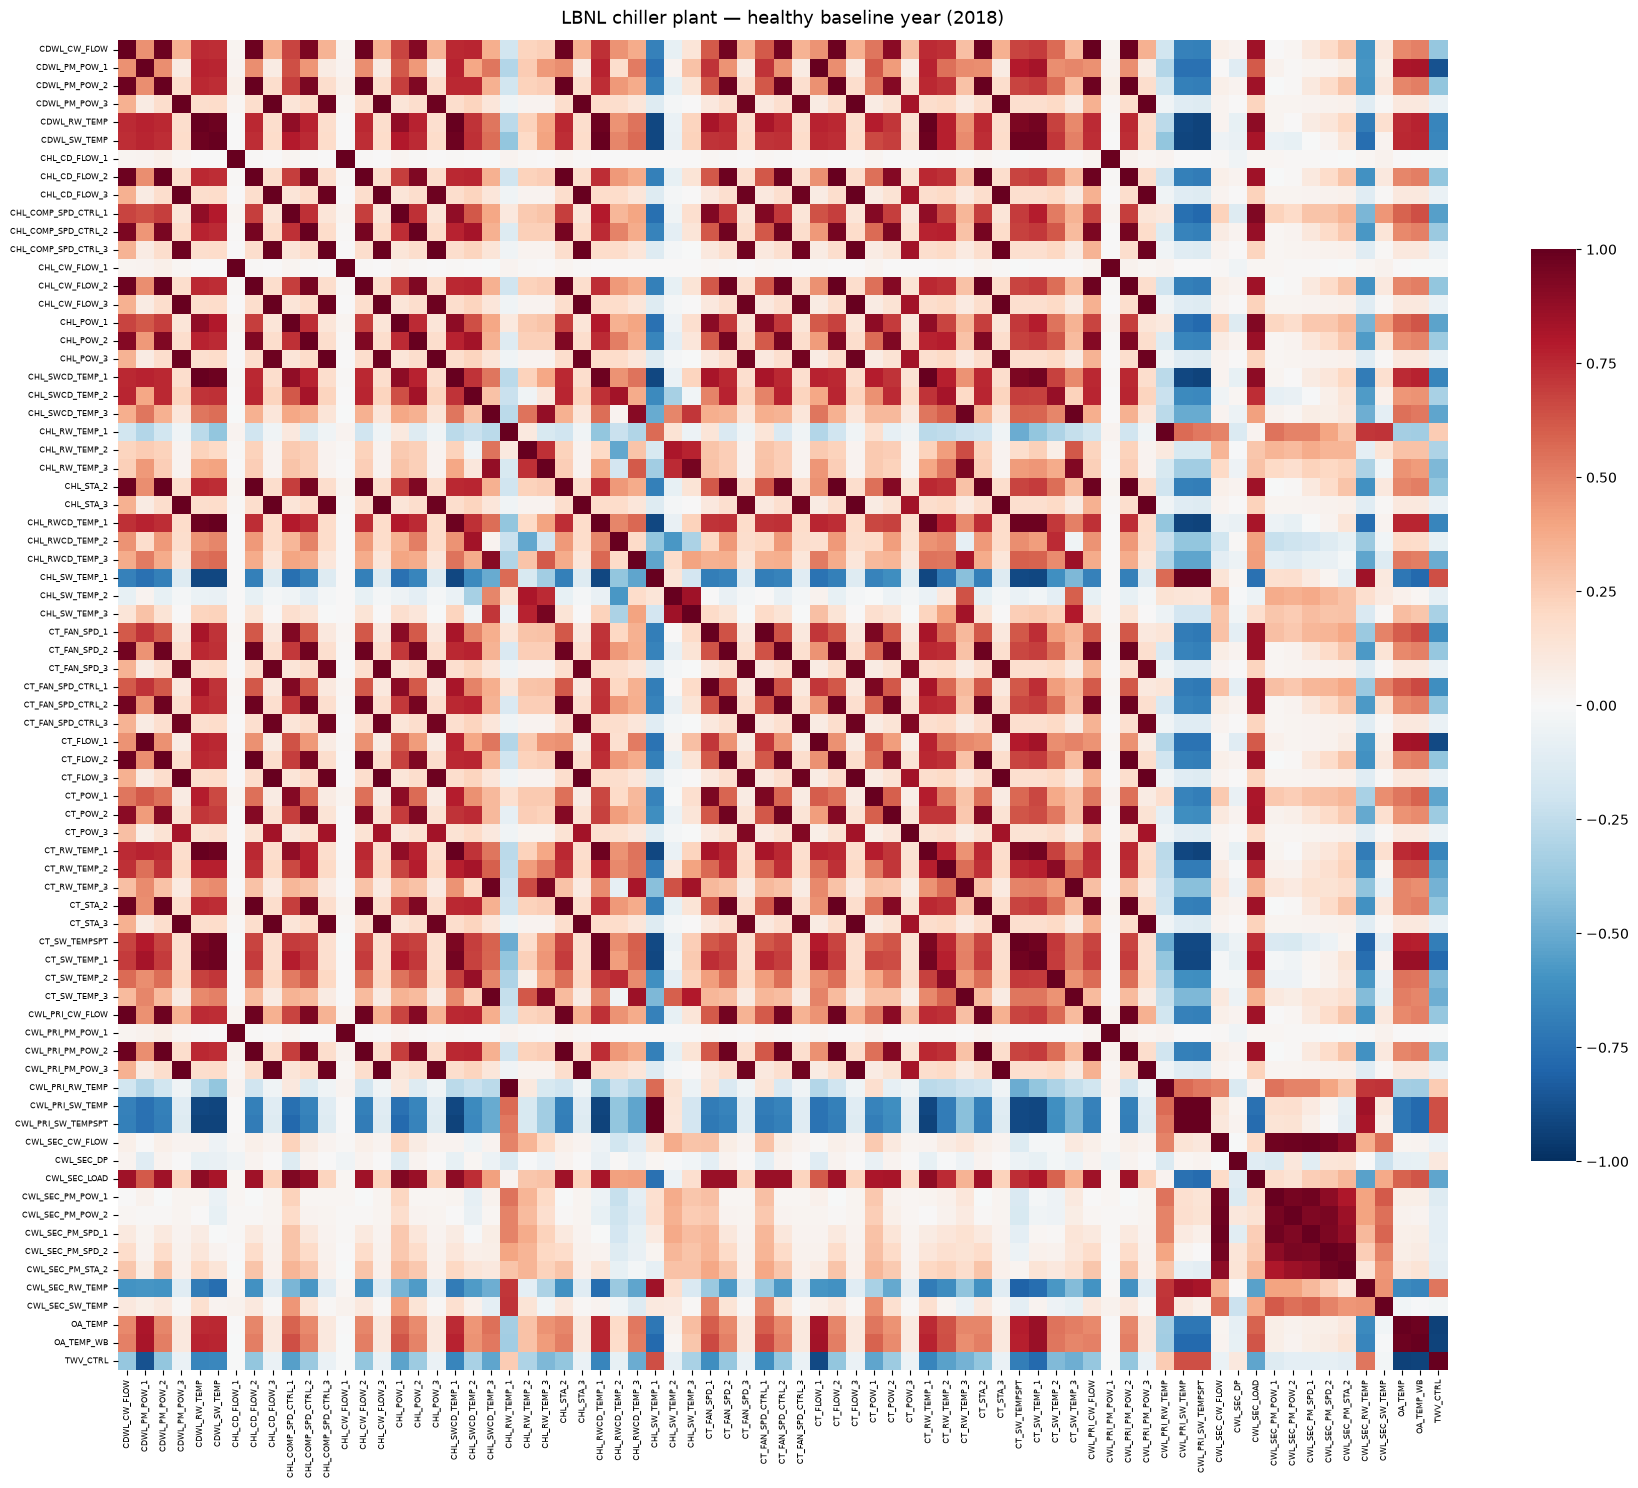

In [12]:
def plot_corr(corr: pl.DataFrame, cols: list[str], title: str, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(18, 16))
    sns.heatmap(
        corr.to_pandas(), xticklabels=cols, yticklabels=cols,
        cmap="RdBu_r", vmin=-1, vmax=1, annot=False, square=True,
        cbar_kws={"shrink": 0.6}, ax=ax,
    )
    ax.set_title(title, fontsize=13, pad=12)
    ax.tick_params(labelsize=6)
    return ax


corr_healthy = healthy.select(sensor_cols).corr()
corr_faulty = faulty.select(sensor_cols).corr()

plot_corr(corr_healthy, sensor_cols, f"LBNL chiller plant — healthy baseline year (2018)")
plt.tight_layout()
plt.show()

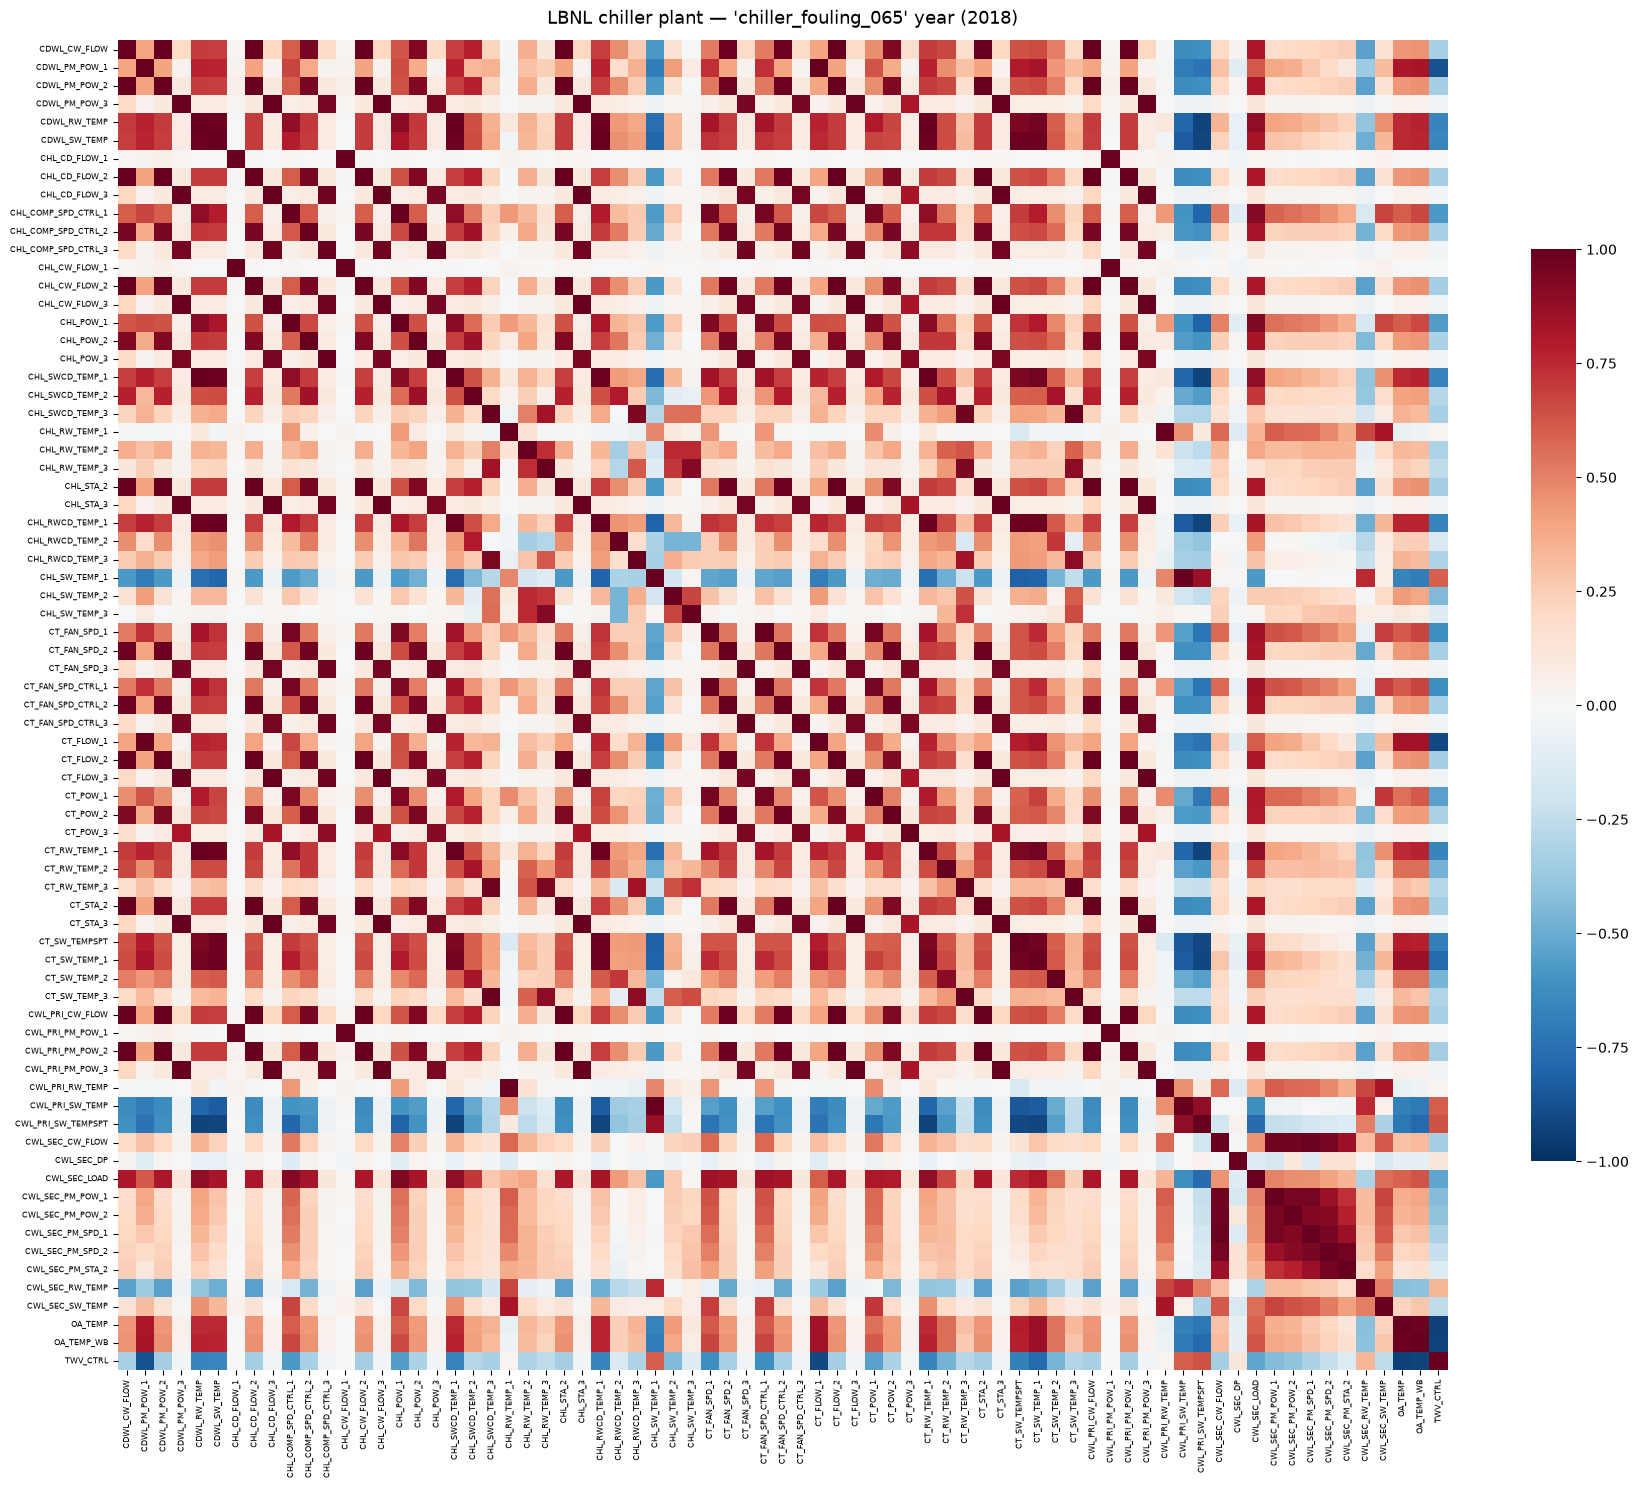

In [13]:
plot_corr(corr_faulty, sensor_cols,
          f"LBNL chiller plant — '{FAULTY}' year (2018)")
plt.tight_layout()
plt.show()

### 4.1 Where the fault changes the correlation structure

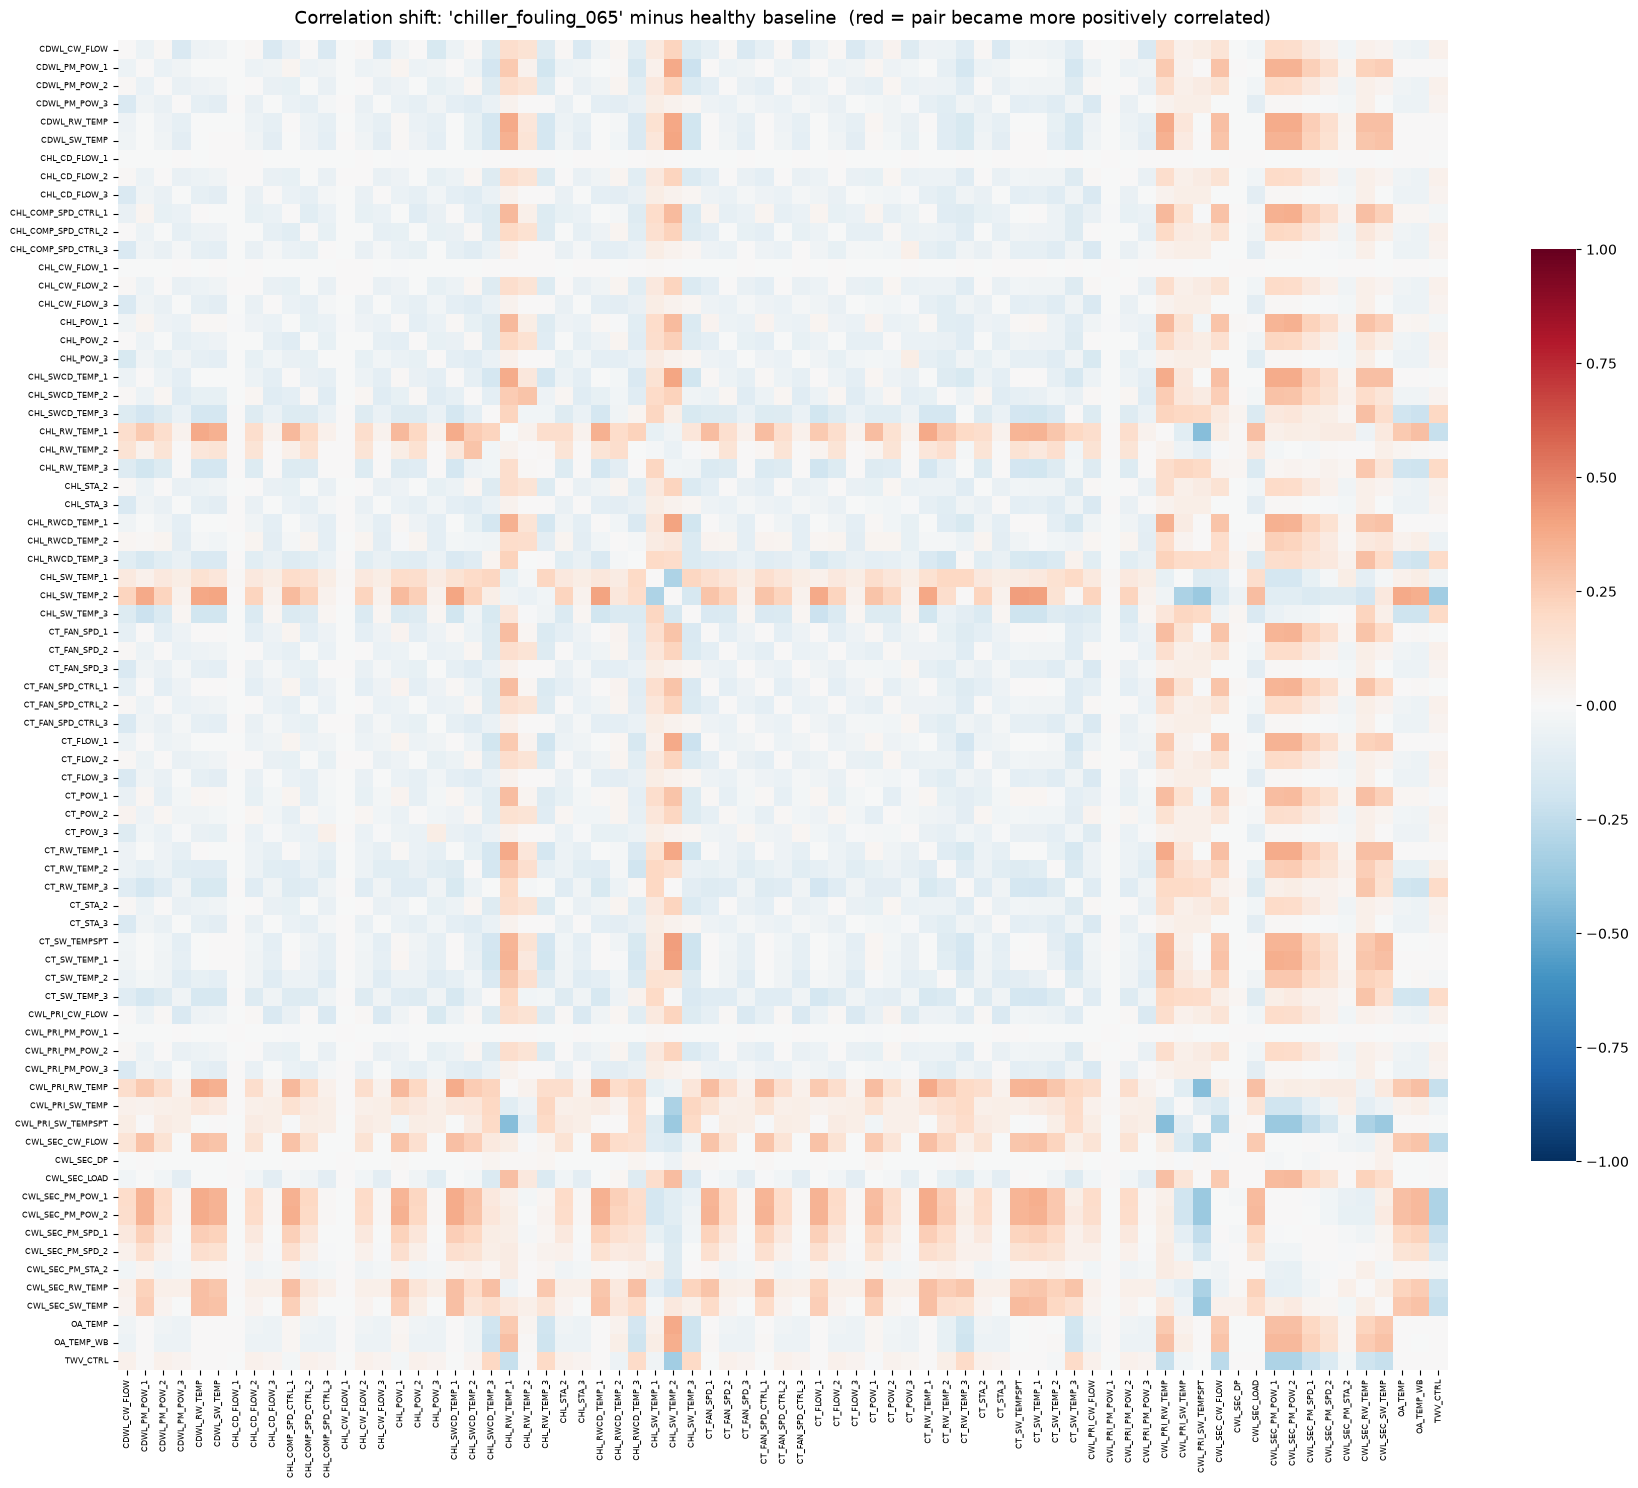

largest single |change| in a correlation coefficient: 0.424


In [14]:
delta_corr = corr_faulty.to_numpy() - corr_healthy.to_numpy()

fig, ax = plt.subplots(figsize=(18, 16))
sns.heatmap(
    delta_corr, xticklabels=sensor_cols, yticklabels=sensor_cols,
    cmap="RdBu_r", vmin=-1, vmax=1, annot=False, square=True,
    cbar_kws={"shrink": 0.6}, ax=ax,
)
ax.set_title(f"Correlation shift: '{FAULTY}' minus healthy baseline  "
             f"(red = pair became more positively correlated)", fontsize=13, pad=12)
ax.tick_params(labelsize=6)
plt.tight_layout()
plt.show()

print(f"largest single |change| in a correlation coefficient: {np.nanmax(np.abs(delta_corr)):.3f}")

### 4.2 Ranked sensor pairs

Same unpivot-and-deduplicate trick as `eda.ipynb` cell 54.

In [15]:
def rank_pairs(corr: pl.DataFrame, cols: list[str]) -> pl.DataFrame:
    return (
        corr.with_columns(pl.Series("sensor_a", cols))
        .unpivot(index="sensor_a", variable_name="sensor_b", value_name="corr")
        .filter(pl.col("sensor_a") != pl.col("sensor_b"))
        .filter(pl.col("sensor_a") > pl.col("sensor_b"))   # deduplicate the mirrored half
        .drop_nans("corr")
        .with_columns(pl.col("corr").abs().alias("abs_corr"))
        .sort("abs_corr", descending=True)
    )


pairs_healthy = rank_pairs(corr_healthy, sensor_cols)

print(f"{pairs_healthy.height} distinct sensor pairs; "
      f"{pairs_healthy.filter(pl.col('abs_corr') > 0.95).height} of them above |r| = 0.95, "
      f"{pairs_healthy.filter(pl.col('abs_corr') < 0.1).height} below |r| = 0.1")

with pl.Config(tbl_rows=30, tbl_cols=-1, fmt_str_lengths=45, float_precision=4):
    display(pairs_healthy.head(30))

2628 distinct sensor pairs; 164 of them above |r| = 0.95, 711 below |r| = 0.1


sensor_a,sensor_b,corr,abs_corr
str,str,f64,f64
"""CHL_CW_FLOW_2""","""CHL_CD_FLOW_2""",1.0000,1.0000
"""CHL_CW_FLOW_3""","""CHL_CD_FLOW_3""",1.0000,1.0000
"""CT_STA_2""","""CHL_STA_2""",1.0000,1.0000
"""CT_FAN_SPD_CTRL_1""","""CT_FAN_SPD_1""",1.0000,1.0000
"""CT_FAN_SPD_CTRL_2""","""CT_FAN_SPD_2""",1.0000,1.0000
"""CT_FAN_SPD_CTRL_3""","""CT_FAN_SPD_3""",1.0000,1.0000
"""CHL_CW_FLOW_1""","""CHL_CD_FLOW_1""",1.0000,1.0000
"""CWL_PRI_CW_FLOW""","""CDWL_CW_FLOW""",1.0000,1.0000
"""CT_STA_3""","""CHL_STA_3""",1.0000,1.0000


In [16]:
pairs_shift = (
    rank_pairs(corr_healthy, sensor_cols).rename({"corr": "corr_healthy"}).drop("abs_corr")
    .join(rank_pairs(corr_faulty, sensor_cols).rename({"corr": "corr_faulty"}).drop("abs_corr"),
          on=["sensor_a", "sensor_b"], how="inner")
    .with_columns((pl.col("corr_faulty") - pl.col("corr_healthy")).alias("delta"))
    .with_columns(pl.col("delta").abs().alias("abs_delta"))
    .sort("abs_delta", descending=True)
    .drop("abs_delta")
)

with pl.Config(tbl_rows=25, tbl_cols=-1, fmt_str_lengths=45, float_precision=4):
    display(pairs_shift.head(25))

sensor_a,sensor_b,corr_healthy,corr_faulty,delta
str,str,f64,f64,f64
"""CWL_PRI_SW_TEMPSPT""","""CWL_PRI_RW_TEMP""",0.5243,0.0999,-0.4245
"""CWL_PRI_SW_TEMPSPT""","""CHL_RW_TEMP_1""",0.5243,0.0999,-0.4244
"""CT_SW_TEMPSPT""","""CHL_SW_TEMP_2""",-0.0655,0.3539,0.4194
"""CT_SW_TEMP_1""","""CHL_SW_TEMP_2""",-0.0389,0.3726,0.4115
"""CHL_SW_TEMP_2""","""CHL_RWCD_TEMP_1""",-0.0720,0.3266,0.3987
"""CHL_SW_TEMP_2""","""CDWL_SW_TEMP""",-0.0736,0.3238,0.3974
"""CHL_SW_TEMP_2""","""CHL_SWCD_TEMP_1""",-0.0633,0.3284,0.3917
"""CHL_SW_TEMP_2""","""CDWL_RW_TEMP""",-0.0636,0.3269,0.3905
"""CT_RW_TEMP_1""","""CHL_SW_TEMP_2""",-0.0636,0.3269,0.3905


## 5. PCA — the three primary components

PCA on **standardised** data is the eigendecomposition of exactly the correlation matrix plotted
above, so the components below *are* the dominant structures of that plot.

As in the ASHRAE notebook, the scaler and the PCA basis are fitted **once, on the healthy year
only** — they are a model of *normal* plant behaviour. The faulty year is then `transform`ed into
that same fixed basis, so:

* the two runs are directly comparable (refitting would give different, sign-ambiguous axes), and
* a PC score reads as a **deviation-from-normal** coordinate, which is what an FDD model needs.

The same three components are then plotted at two zoom levels: the **whole year** and a
**single day**.

In [17]:
X_healthy = healthy.select(sensor_cols).to_numpy()

scaler = StandardScaler().fit(X_healthy)
pca = PCA().fit(scaler.transform(X_healthy))

evr = pca.explained_variance_ratio_
print("Variance captured by the first 10 PCs:")
print(np.round(evr[:10], 4))
print("\nCumulative:")
print(np.round(np.cumsum(evr[:10]), 4))
print(f"\nPC1-PC3 together capture {evr[:3].sum():.1%} of the variance "
      f"of the {len(sensor_cols)} standardised channels.")

Variance captured by the first 10 PCs:
[0.4288 0.1526 0.1133 0.0878 0.0522 0.041  0.0279 0.0232 0.0145 0.0125]

Cumulative:
[0.4288 0.5814 0.6947 0.7825 0.8348 0.8758 0.9038 0.927  0.9415 0.954 ]

PC1-PC3 together capture 69.5% of the variance of the 73 standardised channels.


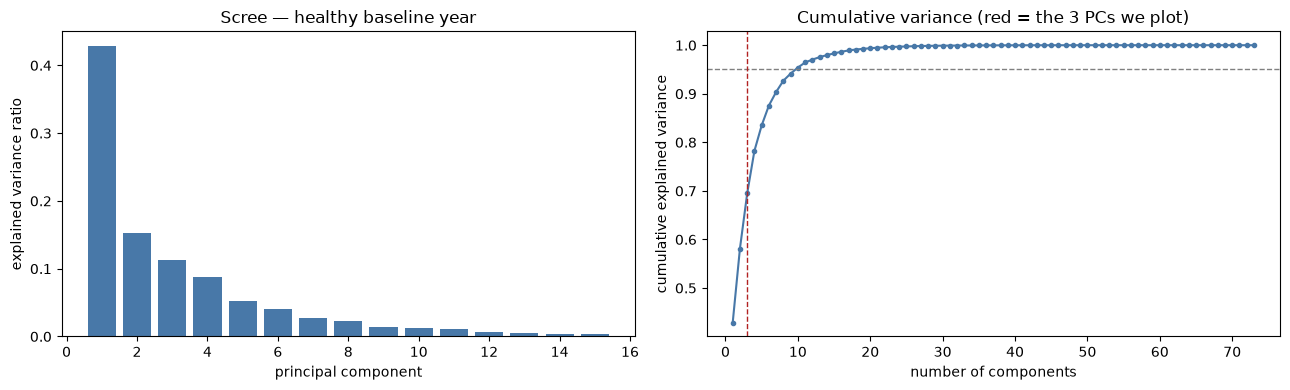

In [18]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.bar(range(1, 16), evr[:15], color="#4878A8")
ax1.set_xlabel("principal component"); ax1.set_ylabel("explained variance ratio")
ax1.set_title("Scree — healthy baseline year")
ax2.plot(range(1, len(evr) + 1), np.cumsum(evr), marker=".", color="#4878A8")
ax2.axhline(0.95, ls="--", lw=1, color="grey")
ax2.axvline(3, ls="--", lw=1, color="firebrick")
ax2.set_xlabel("number of components"); ax2.set_ylabel("cumulative explained variance")
ax2.set_title("Cumulative variance (red = the 3 PCs we plot)")
plt.tight_layout(); plt.show()

### 5.1 What the three components mean

In [19]:
N_PCS = 3
PC_NAMES = [f"PC{i+1}" for i in range(N_PCS)]

loadings = pl.DataFrame(pca.components_[:N_PCS].T, schema=PC_NAMES).with_columns(
    pl.Series("sensor", sensor_cols)
).select("sensor", *PC_NAMES)

for pc in PC_NAMES:
    top = (
        loadings.select("sensor", pc)
        .with_columns(pl.col(pc).abs().alias("abs_loading"))
        .sort("abs_loading", descending=True)
        .head(10)
        .with_columns((pl.col(pc) ** 2).alias("contribution"))
    )
    print(f"=== {pc}  ({evr[PC_NAMES.index(pc)]:.1%} of variance) ===")
    with pl.Config(tbl_rows=-1, fmt_str_lengths=45, float_precision=4):
        display(top.drop("abs_loading"))

=== PC1  (42.9% of variance) ===


sensor,PC1,contribution
str,f64,f64
"""CHL_SWCD_TEMP_1""",0.1693,0.0287
"""CDWL_RW_TEMP""",0.1692,0.0286
"""CT_RW_TEMP_1""",0.1692,0.0286
"""CHL_RWCD_TEMP_1""",0.1664,0.0277
"""CDWL_SW_TEMP""",0.1664,0.0277
"""CT_SW_TEMP_1""",0.1651,0.0273
"""CWL_SEC_LOAD""",0.1647,0.0271
"""CWL_PRI_CW_FLOW""",0.1603,0.0257
"""CDWL_CW_FLOW""",0.1603,0.0257


=== PC2  (15.3% of variance) ===


sensor,PC2,contribution
str,f64,f64
"""CHL_CW_FLOW_3""",0.2835,0.0804
"""CHL_CD_FLOW_3""",0.2835,0.0804
"""CT_FLOW_3""",0.2835,0.0804
"""CHL_STA_3""",0.2834,0.0803
"""CT_STA_3""",0.2834,0.0803
"""CWL_PRI_PM_POW_3""",0.2832,0.0802
"""CDWL_PM_POW_3""",0.2826,0.0799
"""CT_FAN_SPD_3""",0.2821,0.0796
"""CT_FAN_SPD_CTRL_3""",0.2821,0.0796


=== PC3  (11.3% of variance) ===


sensor,PC3,contribution
str,f64,f64
"""CWL_SEC_CW_FLOW""",0.3231,0.1044
"""CWL_SEC_PM_POW_1""",0.3227,0.1041
"""CWL_SEC_PM_SPD_1""",0.3210,0.1031
"""CWL_SEC_PM_POW_2""",0.3166,0.1002
"""CWL_SEC_PM_SPD_2""",0.3042,0.0925
"""CWL_SEC_PM_STA_2""",0.2769,0.0767
"""CWL_PRI_RW_TEMP""",0.2476,0.0613
"""CHL_RW_TEMP_1""",0.2475,0.0613
"""CWL_SEC_SW_TEMP""",0.2448,0.0599


In [20]:
def pc_label(pc: str) -> str:
    top3 = (
        loadings.select("sensor", pc)
        .with_columns(pl.col(pc).abs().alias("a"))
        .sort("a", descending=True)
        .head(3)["sensor"].to_list()
    )
    i = PC_NAMES.index(pc)
    return f"{pc} ({evr[i]:.0%} var) — {', '.join(top3)}"


PC_LABELS = {pc: pc_label(pc) for pc in PC_NAMES}
for v in PC_LABELS.values():
    print(v)

PC1 (43% var) — CHL_SWCD_TEMP_1, CDWL_RW_TEMP, CT_RW_TEMP_1
PC2 (15% var) — CHL_CW_FLOW_3, CHL_CD_FLOW_3, CT_FLOW_3
PC3 (11% var) — CWL_SEC_CW_FLOW, CWL_SEC_PM_POW_1, CWL_SEC_PM_SPD_1


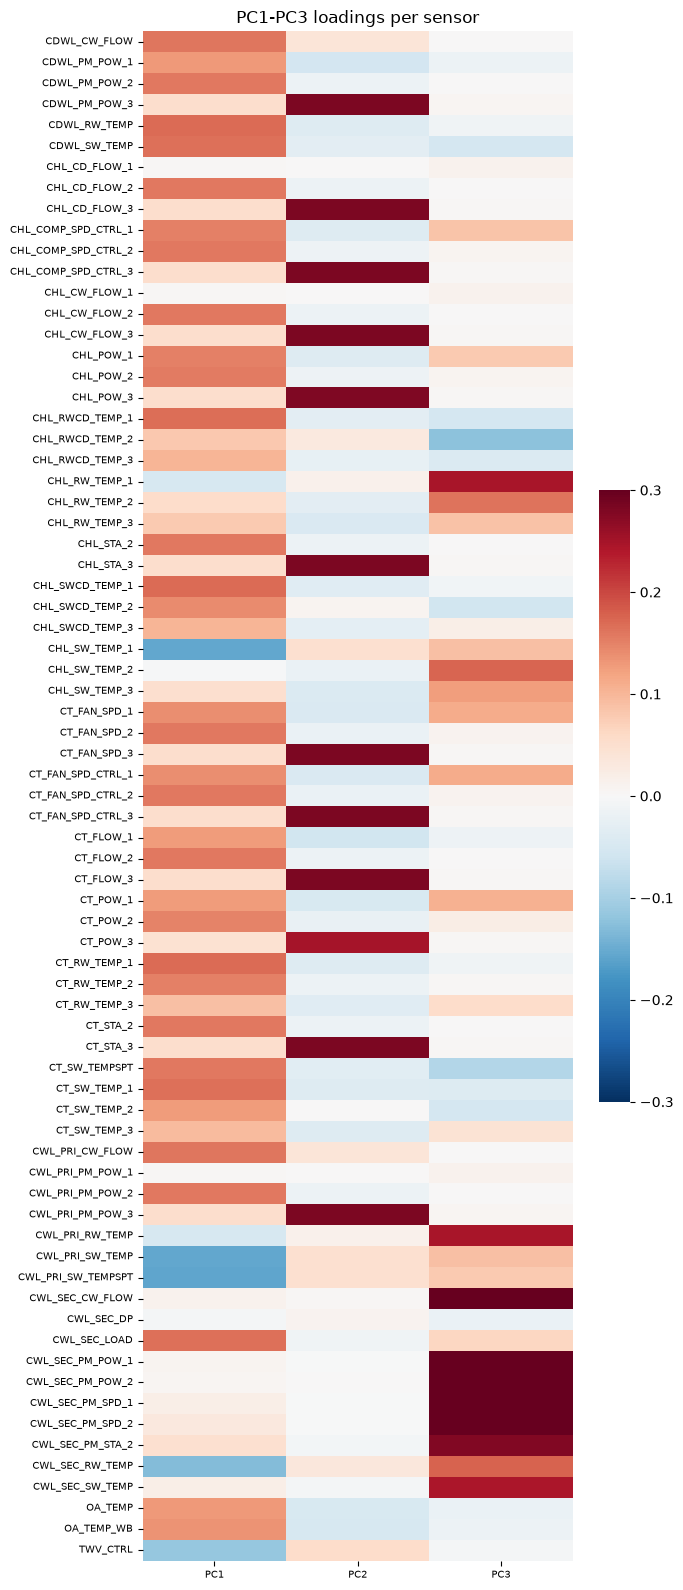

In [21]:
fig, ax = plt.subplots(figsize=(7, 16))
order = loadings.sort("sensor")
sns.heatmap(
    order.select(PC_NAMES).to_pandas(),
    yticklabels=order["sensor"].to_list(), xticklabels=PC_NAMES,
    cmap="RdBu_r", vmin=-0.3, vmax=0.3, center=0, ax=ax, cbar_kws={"shrink": 0.4},
)
ax.set_title("PC1-PC3 loadings per sensor", fontsize=12)
ax.tick_params(labelsize=7)
plt.tight_layout(); plt.show()

**The three components have clean physical readings:**

* **PC1 (43 %) — plant load / weather.** Condenser-water temperatures (`CHL_SWCD_TEMP_1`,
  `CDWL_RW_TEMP`, `CT_RW_TEMP_1`), the tower setpoint, loop flow and `CWL_SEC_LOAD` all load
  together with the same sign. This is one axis: *how hard is the plant working*, which outdoors
  means *how hot is it*. Note that its top loadings **repeat the same physical quantity under
  several names** — `CHL_SWCD_TEMP_1`, `CDWL_RW_TEMP` and `CT_RW_TEMP_1` are the same water
  temperature published by three subsystems (their pairwise |r| is 1.000, see §4.2), as are
  `CWL_PRI_CW_FLOW` and `CDWL_CW_FLOW`. Each duplicate double-weights its variable in a
  standardised PCA, so PC1 is somewhat *more* dominant than the physics alone would make it. We
  keep them, because dropping channels would make the correlation matrix less faithful to what is
  actually in the file — but it is worth knowing before reading the loading magnitudes.
* **PC2 (15 %) — chiller 3 staging.** Every one of its top loadings is a unit-3 channel — flow,
  status, pump power, fan speed, compressor command. Chiller 3 runs 0.44 % of the year, so this
  component is essentially a binary indicator that fires on those rare hours.
* **PC3 (11 %) — the secondary (building-side) loop.** Secondary flow, both secondary pump
  powers and speeds, pump 2 staging, and the primary/secondary return temperatures. It is the
  *distribution* side of the plant, decoupled from the production side.

Note what this means for fault detection: the **top two components are dominated by operating
mode**, not by health. A health indicator built naively on PC1 would mostly be a thermometer.

### 5.2 PC1–PC3 over the **whole timespan** (the full 2018 year)

Both years are projected into the healthy basis. 525 540 points × 3 components × 2 runs would
bloat the notebook and render as a solid block of ink, so the **year view is resampled to hourly
means** — the diurnal and seasonal structure is fully preserved at that resolution. The
single-day view in §5.3 keeps the native 1-minute samples.

In [22]:
def project(df: pl.DataFrame, run: str) -> pl.DataFrame:
    # project a frame into the healthy PCA basis, keeping the timestamp
    scores = pca.transform(scaler.transform(df.select(sensor_cols).to_numpy()))[:, :N_PCS]
    return (
        df.select("Datetime")
        .hstack(pl.DataFrame(scores, schema=PC_NAMES))
        .with_columns(pl.lit(run).alias("run"))
    )


pc_all = pl.concat([
    project(healthy, f"healthy · {HEALTHY}"),
    project(faulty, f"faulty · {FAULTY}"),
])

pc_hourly = (
    pc_all.sort("Datetime")
    .group_by_dynamic("Datetime", every="1h", group_by="run")
    .agg(pl.col(PC_NAMES).mean())
)

print(f"native: {pc_all.height:,} rows   ->   hourly for plotting: {pc_hourly.height:,} rows")
pc_hourly.head()

native: 1,051,080 rows   ->   hourly for plotting: 17,518 rows


run,Datetime,PC1,PC2,PC3
str,datetime[μs],f64,f64,f64
"""healthy · baseline""",2018-01-01 01:00:00,-2.12212,0.298351,3.624107
"""healthy · baseline""",2018-01-01 02:00:00,-3.349747,0.685641,1.966628
"""healthy · baseline""",2018-01-01 03:00:00,-3.814938,0.843604,1.523016
"""healthy · baseline""",2018-01-01 04:00:00,-4.127919,0.943867,0.001334
"""healthy · baseline""",2018-01-01 05:00:00,-4.274744,0.971968,-1.650852


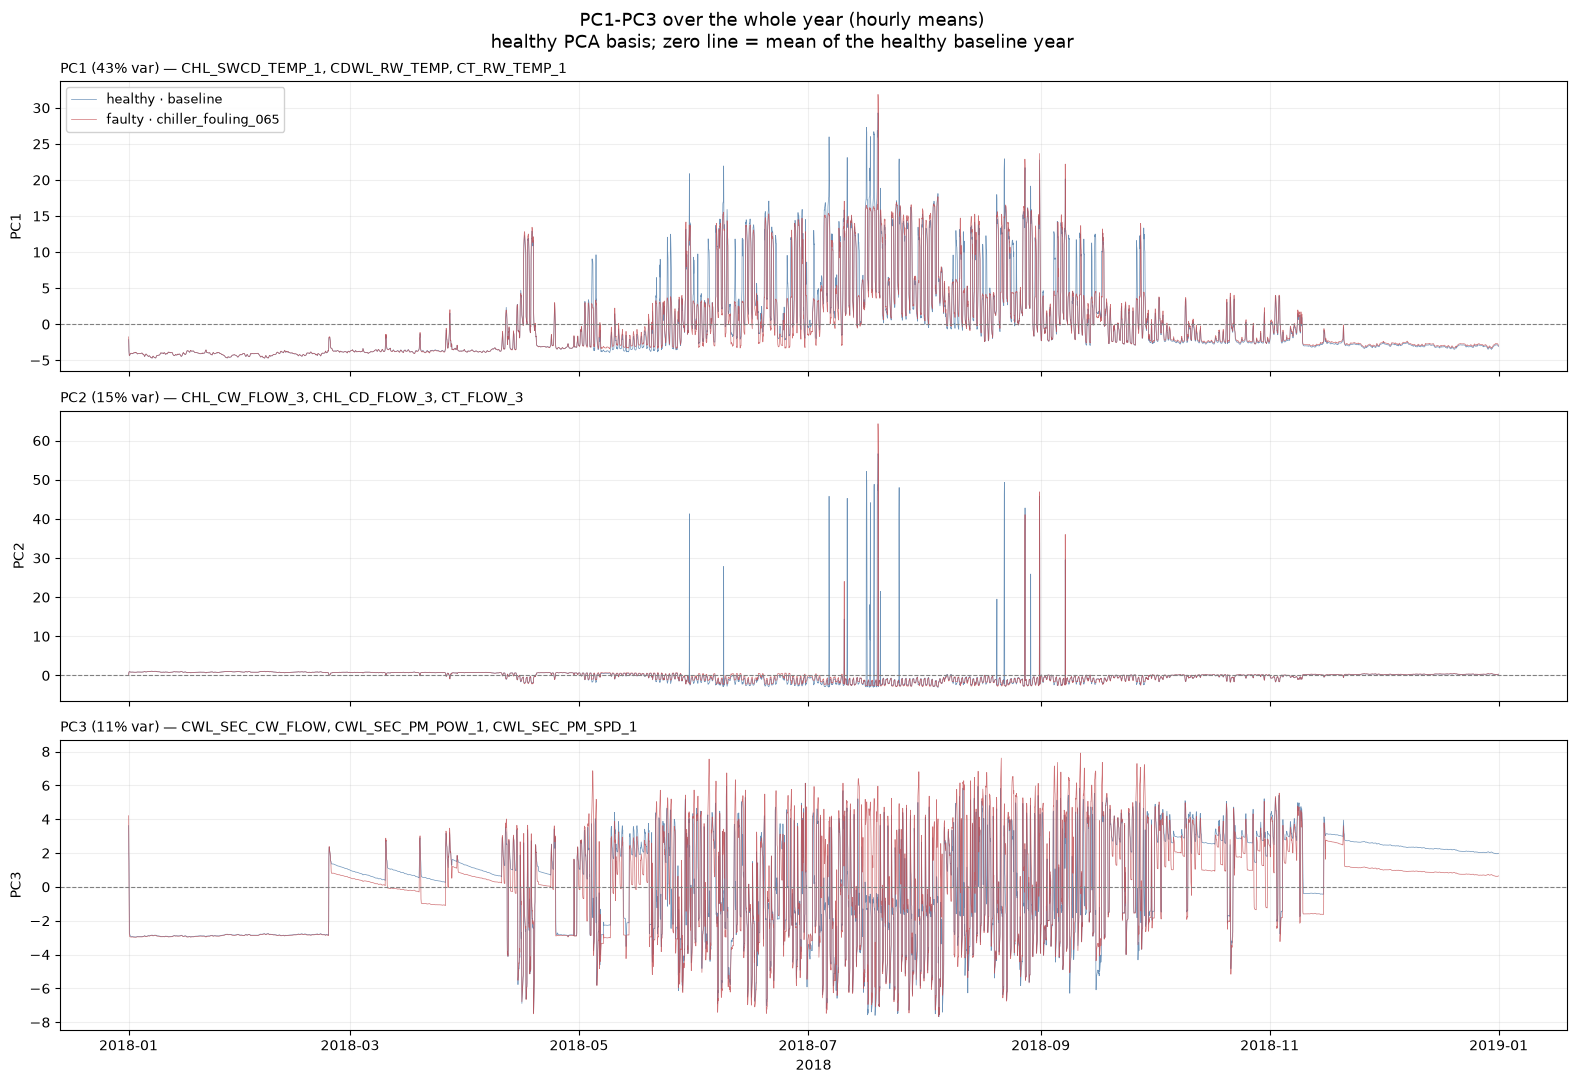

In [23]:
runs = pc_all["run"].unique(maintain_order=True).to_list()
colors = {runs[0]: "#4878A8", runs[1]: "#C44E52"}

fig, axes = plt.subplots(N_PCS, 1, figsize=(16, 11), sharex=True)
for ax, pc in zip(axes, PC_NAMES):
    for run in runs:
        sub = pc_hourly.filter(pl.col("run") == run).sort("Datetime")
        ax.plot(sub["Datetime"], sub[pc], lw=0.5, alpha=0.8, color=colors[run], label=run)
    ax.axhline(0, lw=0.8, color="grey", ls="--")
    ax.set_ylabel(pc)
    ax.set_title(PC_LABELS[pc], fontsize=10, loc="left")
    ax.grid(alpha=0.2)
axes[0].legend(loc="upper left", fontsize=9, framealpha=0.9)
axes[-1].set_xlabel("2018")
fig.suptitle("PC1-PC3 over the whole year (hourly means)\n"
             "healthy PCA basis; zero line = mean of the healthy baseline year", fontsize=13)
plt.tight_layout(); plt.show()

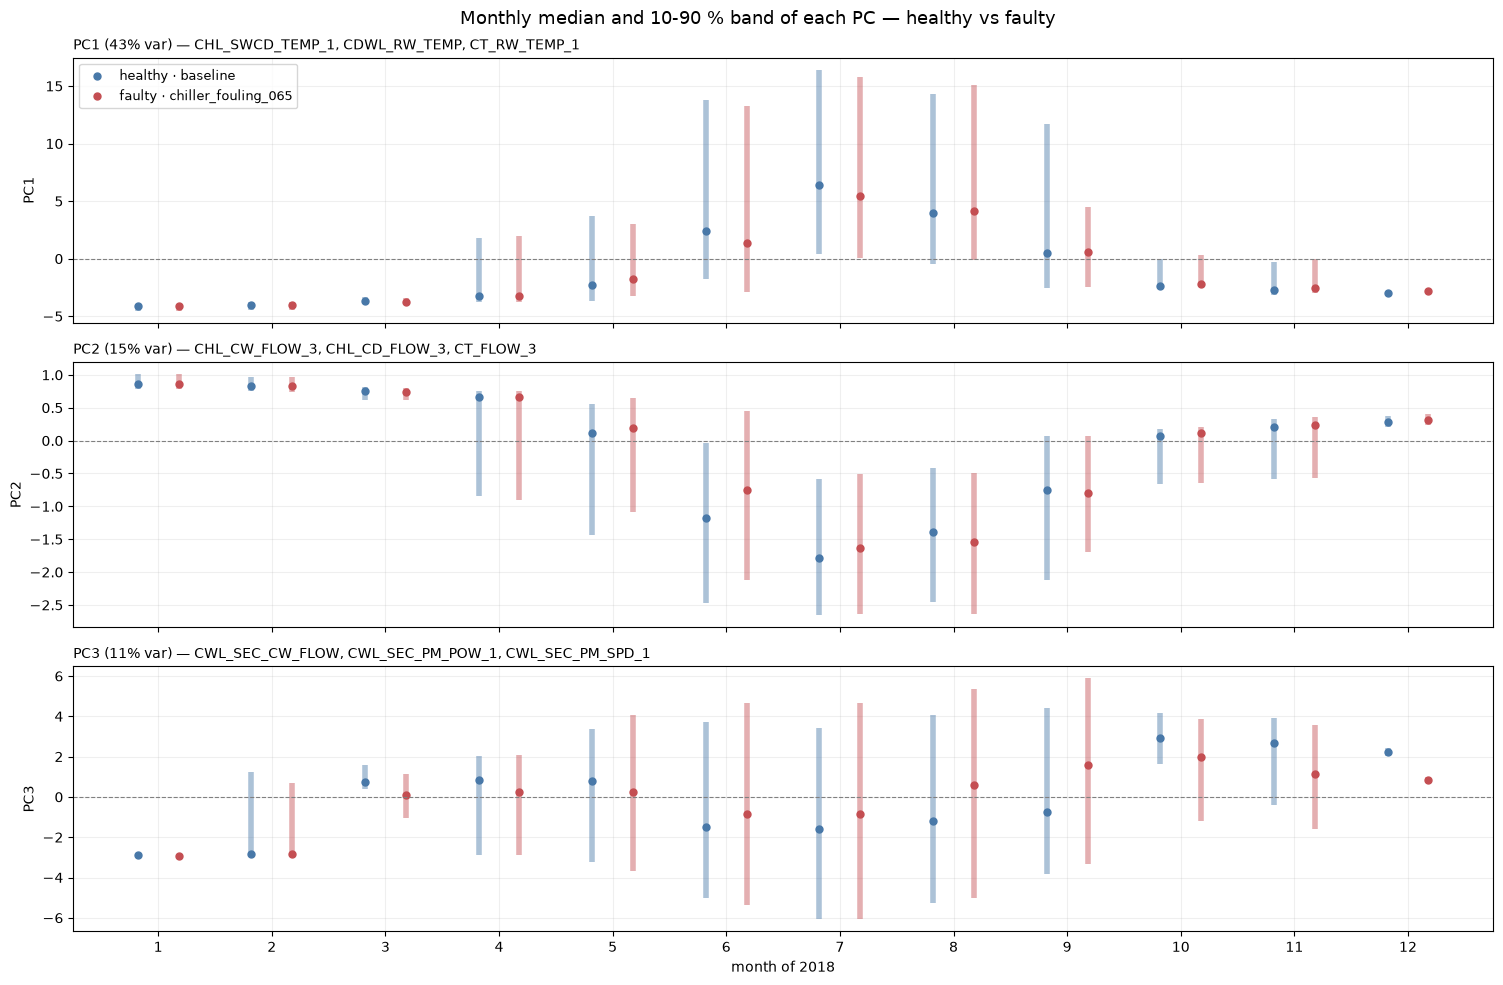

In [24]:
# monthly distribution of each PC, which makes the seasonal envelope explicit
monthly = pc_all.with_columns(pl.col("Datetime").dt.month().alias("month"))

fig, axes = plt.subplots(N_PCS, 1, figsize=(15, 10), sharex=True)
for ax, pc in zip(axes, PC_NAMES):
    for run, off in zip(runs, [-0.18, 0.18]):
        stats = (
            monthly.group_by("run", "month")
            .agg(pl.col(pc).quantile(0.1).alias("lo"),
                 pl.col(pc).median().alias("mid"),
                 pl.col(pc).quantile(0.9).alias("hi"))
            .filter(pl.col("run") == run).sort("month")
        )
        x = stats["month"].to_numpy() + off
        ax.vlines(x, stats["lo"], stats["hi"], color=colors[run], lw=4, alpha=0.45)
        ax.plot(x, stats["mid"], "o", ms=5, color=colors[run], label=run)
    ax.axhline(0, lw=0.8, color="grey", ls="--")
    ax.set_ylabel(pc); ax.grid(alpha=0.2)
    ax.set_title(PC_LABELS[pc], fontsize=10, loc="left")
axes[0].legend(loc="upper left", fontsize=9)
axes[-1].set_xlabel("month of 2018"); axes[-1].set_xticks(range(1, 13))
fig.suptitle("Monthly median and 10-90 % band of each PC — healthy vs faulty", fontsize=13)
plt.tight_layout(); plt.show()

**Read-out of the year view.**

* **PC1 traces the cooling season directly** — flat and negative from January to March, rising
  through spring, peaking in July/August at +30, falling back by December. The healthy and faulty
  traces sit almost on top of each other at this scale.
* **PC2 is silent except for a handful of summer spikes** — exactly the rare hours when chiller 3
  stages on. Note these spikes appear in *both* runs but not at the same moments: the fouled
  plant needs its third chiller at different times, which is itself a fault signature.
* **PC3 shows the secondary loop's own regime**, with a distinctive slow saw-tooth in the
  shoulder months and heavy 1-minute activity through the cooling season.
* The seasonal envelope is the practical warning: a fixed threshold on any of these components
  would fire every August and never in January. **Normalise against operating conditions before
  thresholding.**

### 5.3 PC1–PC3 over a **single day**

For the day we pick the **peak-load day of the year** — the day with the highest mean secondary
cooling load. That is where the plant is working hardest, all staged units are running, and a
fouling fault has the most room to show itself. Full 1-minute resolution, no resampling.

In [25]:
peak_day = (
    healthy.group_by(pl.col("Datetime").dt.date().alias("day"))
    .agg(pl.col("CWL_SEC_LOAD").mean().alias("mean_load"))
    .sort("mean_load", descending=True)
)

with pl.Config(tbl_rows=5, float_precision=1):
    display(peak_day.head(5))

DAY = peak_day["day"][0]
print(f"single day chosen: {DAY}")

day,mean_load
date,f64
2018-07-19,468689.5
2018-07-18,461875.0
2018-07-16,457908.3
2018-07-06,454960.1
2018-07-17,453028.7


single day chosen: 2018-07-19


In [26]:
day = pc_all.filter(pl.col("Datetime").dt.date() == DAY)

long = day.unpivot(
    index=["Datetime", "run"], on=PC_NAMES,
    variable_name="component", value_name="score",
).with_columns(pl.col("component").replace(PC_LABELS).alias("component_label"))

fig = px.line(
    long.sort("Datetime").to_pandas(),
    x="Datetime", y="score", color="run", facet_row="component_label",
    height=850,
    color_discrete_map={runs[0]: "#4878A8", runs[1]: "#C44E52"},
    labels={"Datetime": "time of day", "score": "PC score"},
    title=f"PC1-PC3 over a single day ({DAY}, peak cooling load) — 1-minute resolution",
)
fig.update_yaxes(matches=None)
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1], font_size=10))
fig.update_layout(legend=dict(orientation="h", y=1.06, x=0), margin=dict(t=140))
fig.show()

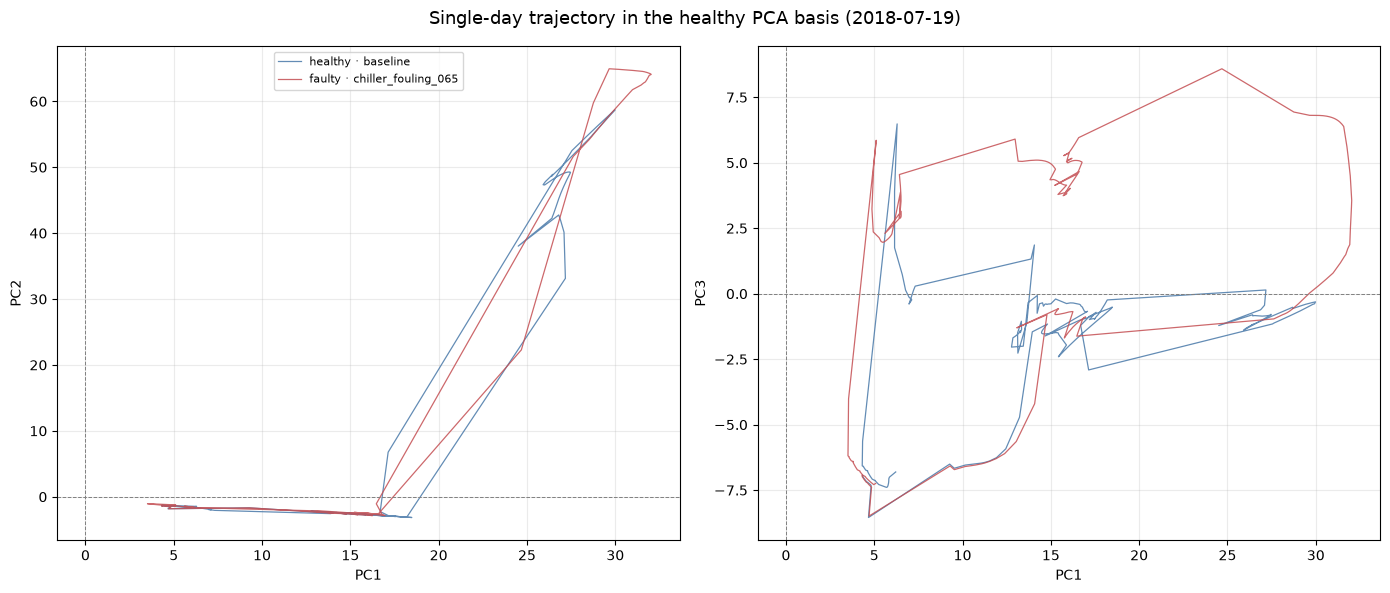

In [27]:
# the same day as a trajectory in the PC planes
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (xa, ya) in zip(axes, [("PC1", "PC2"), ("PC1", "PC3")]):
    for run in runs:
        sub = day.filter(pl.col("run") == run).sort("Datetime")
        ax.plot(sub[xa], sub[ya], lw=0.9, alpha=0.85, color=colors[run], label=run)
    ax.axhline(0, lw=0.7, color="grey", ls="--"); ax.axvline(0, lw=0.7, color="grey", ls="--")
    ax.set_xlabel(xa); ax.set_ylabel(ya); ax.grid(alpha=0.25)
axes[0].legend(fontsize=8)
fig.suptitle(f"Single-day trajectory in the healthy PCA basis ({DAY})", fontsize=13)
plt.tight_layout(); plt.show()

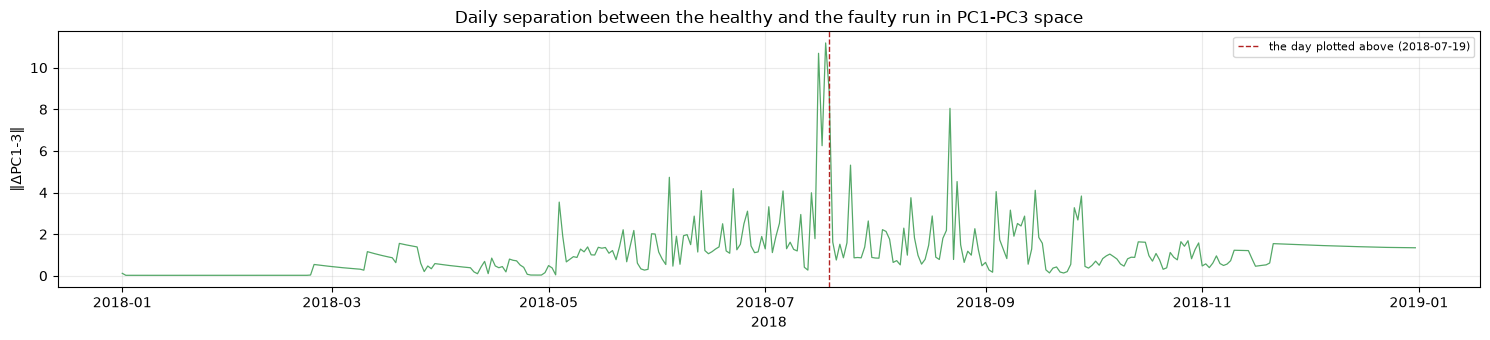

shape: (1, 3)
┌──────────┬──────────┬───────────┐
│ mean     ┆ median   ┆ max       │
│ ---      ┆ ---      ┆ ---       │
│ f64      ┆ f64      ┆ f64       │
╞══════════╪══════════╪═══════════╡
│ 1.131305 ┆ 0.878135 ┆ 11.190102 │
└──────────┴──────────┴───────────┘


In [28]:
# how separable are the two runs on any given day? distance between the daily PC centroids
daily = (
    pc_all.group_by("run", pl.col("Datetime").dt.date().alias("day"))
    .agg(pl.col(PC_NAMES).mean())
    .sort("day")
)
h = daily.filter(pl.col("run") == runs[0]).drop("run")
f = daily.filter(pl.col("run") == runs[1]).drop("run")
sep = h.join(f, on="day", suffix="_f").with_columns(
    (sum((pl.col(pc) - pl.col(f"{pc}_f")) ** 2 for pc in PC_NAMES)).sqrt().alias("centroid_distance")
)

fig, ax = plt.subplots(figsize=(15, 3.5))
ax.plot(sep["day"], sep["centroid_distance"], lw=0.9, color="#55A868")
ax.axvline(DAY, color="firebrick", ls="--", lw=1, label=f"the day plotted above ({DAY})")
ax.set_ylabel("‖ΔPC1-3‖"); ax.set_xlabel("2018"); ax.grid(alpha=0.25); ax.legend(fontsize=8)
ax.set_title("Daily separation between the healthy and the faulty run in PC1-PC3 space", fontsize=12)
plt.tight_layout(); plt.show()

print(sep.select(
    pl.col("centroid_distance").mean().alias("mean"),
    pl.col("centroid_distance").median().alias("median"),
    pl.col("centroid_distance").max().alias("max"),
))

**Read-out of the single-day and separation views.** On 2018-07-19 the two runs trace visibly
different paths — this is the day of **maximum separation in the whole year** (‖ΔPC1-3‖ ≈ 11.2
against a yearly median of 0.88).

The separation curve is the most actionable plot in this notebook: the fault is **undetectable in
January and February** (separation ≈ 0, the plant is barely loaded so fouling has no consequence),
becomes visible from March, and is largest in July. The same fault, the same severity, the same
sensors — and a detector's chance of catching it varies by an order of magnitude with the season.

**When you sample matters as much as what you measure.** Any evaluation of an FDD method on this
dataset that pools the whole year will report an average that describes no actual operating
condition.

## 6. Summary — what to remember about the LBNL chiller plant data

**Structure**
* 24 scenario files in one zip: **1 fault-free baseline + 23 fault cases** across 8 fault
  families, including **sensor-bias** and **control** faults that RP-1043 does not cover.
* Each file: **525 540 rows × 77 channels, 1-minute sampling, 2018-01-01 01:00 → 2018-12-31
  23:59** — a full simulated year of a three-chiller plant.
* All scenarios share identical timestamps, so baseline and fault are a **true paired
  counterfactual**: you can subtract them sample by sample.
* **≈ 10.3 GB uncompressed.** Stream the members you need from the zip; do not extract the
  archive.

**Quality**
* **Perfectly regular cadence, no gaps, no duplicate timestamps, zero nulls, zero NaNs** — it is
  simulation output. Note the year is short its first hour (warm-up), so it is 525 540 rows and
  not 525 600.
* Four channels are constant (`CHL_STA_1`, `CT_STA_1`, `CWL_SEC_PM_STA_1`, `CWL_SEC_DPSPT`) and
  must be dropped before correlation/PCA.
* Units are undocumented but partly recoverable: `CWL_SEC_LOAD` is verified to be thermal power
  in **watts** (it equals `flow x 500 x dT` BTU/h to within 0.1 %), so flows are gpm and
  temperatures °F. The `*_POW_*` channels' absolute scale does **not** check out as kW — the
  implied plant COP would be ~1 — so use them as ratios, not as absolute energy.
* No corrupted values, no sentinel encodings — the opposite of both `eda.ipynb` and the ASHRAE
  workbooks. Treat this dataset as a *method-development* environment, not as evidence that a
  pipeline can survive real telemetry.

**Structure of the signal**
* **Operating mode, not health, dominates the variance.** Chiller 1 runs 100 % of the year,
  chiller 2 12.4 %, chiller 3 only 0.44 %, so every unit-2 and unit-3 channel is zero most of the
  time and strictly bimodal. The first three PCs (69.5 % of the variance of 73 channels) read as
  **PC1 = load/weather (43 %)**, **PC2 = chiller-3 staging (15 %)**, **PC3 = secondary loop
  (11 %)** — none of them is a health axis.
* The channels are **massively redundant**: 164 of the 2628 pairs exceed |r| = 0.95, many at
  exactly 1.000 because the model reports the same physical quantity under two names
  (`CHL_CW_FLOW_1` ≡ `CHL_CD_FLOW_1`, `CT_FAN_SPD_n` ≡ `CT_FAN_SPD_CTRL_n`,
  `CWL_PRI_CW_FLOW` ≡ `CDWL_CW_FLOW`). At the same time 711 pairs sit below |r| = 0.1 — the
  structure is block-wise, not global.
* There is a strong **seasonal envelope** on all three components. Any threshold on a raw PC score
  fires every August and never in January; normalise against operating conditions (load, outdoor
  wet-bulb, chillers staged) first.
* The fouling fault is **expensive but quiet**: +6.7 % annual plant energy use and −4.1 % cooling
  delivered (≈ +11 % energy per unit cooling), yet no single channel shifts by even 0.4 σ and the
  largest change in any correlation coefficient is 0.42. It shows as a *persistent offset* whose
  detectability tracks the season — ≈ 0 in January, maximal in July. **When you sample matters as
  much as what you measure.**